# 5. A binary supermassive black hole

One particularly interesting astronomical scenario is supermassive black hole binaries. Here we model a total mass of 10⁸ M☉ (mass ratio 0.5) on a circular orbit of 0.05 pc (a period of about a century), at 20 Mpc, where the separation is 0.5 mas.

* each black hole has a **corona** (a lamp moving with the orbit, with its own variability driver) and a **mini-disc** (a `FlaredDisc` inside its Roche lobe, Keplerian about its own hole and moving with it);
* a **circumbinary disc** (a `FlaredDisc` from 2a to 8a) surrounds the pair.

Both coronae light all three discs, so every disc has one reflection layer per corona (`smbhb_<disc>_<corona>`), each with that corona's driver, Doppler factors and delays. Nothing here is specific to black holes: there is no general relativity (no lensing, no gravitational redshift), only special-relativistic Doppler factors and light-travel delays. This is pretty crude, but it's also only a toy model to start thinking about what these systems would look like through an X-ray interferometer.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

import xrimodel as xm
from xrimodel.engine import FlaredDisc, KeplerOrbit, Lamp, Scene, System3D
from xrimodel.units import UAS_PER_RAD

M1, M2, A_PC, D_PC = 6.67e7, 3.33e7, 0.05, 20e6
orb = KeplerOrbit(m1=M1, m2=M2, a=A_PC, length_unit="pc")
s0 = orb.state(0.0)
v_rel = np.linalg.norm(s0["v2"] - s0["v1"])
print(f"period {orb.period_days / 365.25:.0f} yr, relative orbital speed {v_rel:.0f} km/s")
uas_per_pc = 3.0857e18 / (D_PC * 3.0857e18) * UAS_PER_RAD

# Roche-lobe radii (Eggleton 1983) set the mini-discs' outer edges
q = M2 / M1
rl = lambda q: 0.49 * q ** (2 / 3) / (0.6 * q ** (2 / 3) + np.log(1 + q ** (1 / 3)))  # noqa: E731
r_out1, r_out2 = 0.5 * rl(1 / q) * A_PC, 0.5 * rl(q) * A_PC
pl = lambda norm: {"kind": "powerlaw", "gamma": 1.9, "norm": norm}  # noqa: E731
inc, node = 30.0, 20.0


def smbhb(phase):
    s = orb.state(phase)
    r1, r2, v1, v2 = (tuple(map(float, s[k])) for k in ("r1", "r2", "v1", "v2"))
    return System3D(
        name="smbhb", length_unit="pc", inclination=inc, node_pa=node,
        lamps=[Lamp(name="corona1", spectrum=pl(2e-3), position=r1, velocity=v1, driver="bh1"),
               Lamp(name="corona2", spectrum=pl(1e-3), position=r2, velocity=v2, driver="bh2")],
        bodies=[FlaredDisc(name="disc1", centre=r1, r_in=5e-4, r_out=r_out1, h_over_r=0.05,
                           mass_msun=M1, velocity=v1, albedo=0.2),
                FlaredDisc(name="disc2", centre=r2, r_in=5e-4, r_out=r_out2, h_over_r=0.05,
                           mass_msun=M2, velocity=v2, albedo=0.2),
                FlaredDisc(name="cbd", r_in=2 * A_PC, r_out=8 * A_PC, h_over_r=0.08,
                           mass_msun=M1 + M2, albedo=0.2)],
        supersample=2)


def sky(system, r):
    f, (u_a, u_b) = system.frame(), system.sky_axes()
    r = np.asarray(r)
    return ((r @ f["e_a"]) * u_a + (r @ f["e_b"]) * u_b) * uas_per_pc


def render(phase, root=9000.0, level=10):
    system = smbhb(phase)
    s = orb.state(phase)
    holes = [sky(system, s["r1"]), sky(system, s["r2"])]
    grid = xm.QuadtreeGrid.refine(   # fine near the holes (mini-discs ~0.1 mas), coarse elsewhere
        root, lambda x, y, sz: np.minimum(*(np.hypot(x - h[0], y - h[1]) for h in holes))
        < 3 * sz + 150.0,
        max_level=level, min_level=7)
    scene = Scene(ra=150.0, dec=20.0, distance_pc=D_PC, grid=grid)
    f = np.geomspace(1e-9, 1e-6, 200)
    for name, seed in (("bh1", 1), ("bh2", 2)):
        scene.add_driver(xm.PSDDriver(f, xm.broken_powerlaw_psd(f, rms=0.3, f_break=1e-7),
                                      name=name, seed=seed))
    scene.add(system)
    return scene.render(), holes

period 105 yr, relative orbital speed 2933 km/s


## The pair and its circumbinary disc

It would be very expensive to model a grid fine enough for both the black holes and the circumbinary disc. Therefore, we instead model these on an adaptive grid where the pixel sizes at the black holes are much smaller (9 µas) than at the circumbinary disc (70 µas). Here we show the reflected light at phase 0. The inner part of the circumbinary disc stays dark: the coronae sit in the planes of their own flared mini-discs, which shadow the low elevations at which they would see it.

In [2]:
m0, holes0 = render(0.0)
for L in m0.layers:
    print(f"{L.name:22s} {L.mean_photon_flux():.2e} photons/s/cm^2")

reg = xm.RegularGrid(nx=300, ny=300, scale=30.0)   # 30 uas pixels for display


def resample(layers):
    # surface brightness (photons/s/cm2/sr) of quadtree layers on the regular display grid:
    # leaves smaller than a display pixel add their flux to the pixel holding their centre,
    # larger ones spread it over the pixels they cover
    n, sc = reg.nx, reg.scale
    half = n * sc / 2
    flux = np.zeros((n, n))
    for L in layers:
        x, y = L.grid.centres()
        sz, v = L.grid.sizes(), L.maps["NORM"]
        small = sz <= sc
        col = np.floor((half - x[small]) / sc).astype(int)
        row = np.floor((y[small] + half) / sc).astype(int)
        ok = (col >= 0) & (col < n) & (row >= 0) & (row < n)
        np.add.at(flux, (row[ok], col[ok]), v[small][ok])
        for xi, yi, si, vi in zip(x[~small], y[~small], sz[~small], v[~small]):
            c0, c1 = int(np.floor((half - xi - si / 2) / sc)), int(np.ceil((half - xi + si / 2) / sc))
            r0, r1 = int(np.floor((yi - si / 2 + half) / sc)), int(np.ceil((yi + si / 2 + half) / sc))
            c0, r0, c1, r1 = max(c0, 0), max(r0, 0), min(c1, n), min(r1, n)
            if c1 > c0 and r1 > r0:
                flux[r0:r1, c0:c1] += vi * sc**2 / si**2
    return flux / (sc / UAS_PER_RAD) ** 2

smbhb_disc1_corona1    2.07e-04 photons/s/cm^2
smbhb_disc2_corona2    9.23e-05 photons/s/cm^2
smbhb_cbd_corona1      5.99e-05 photons/s/cm^2
smbhb_cbd_corona2      3.63e-05 photons/s/cm^2
smbhb_corona1          6.36e-03 photons/s/cm^2
smbhb_corona2          3.13e-03 photons/s/cm^2


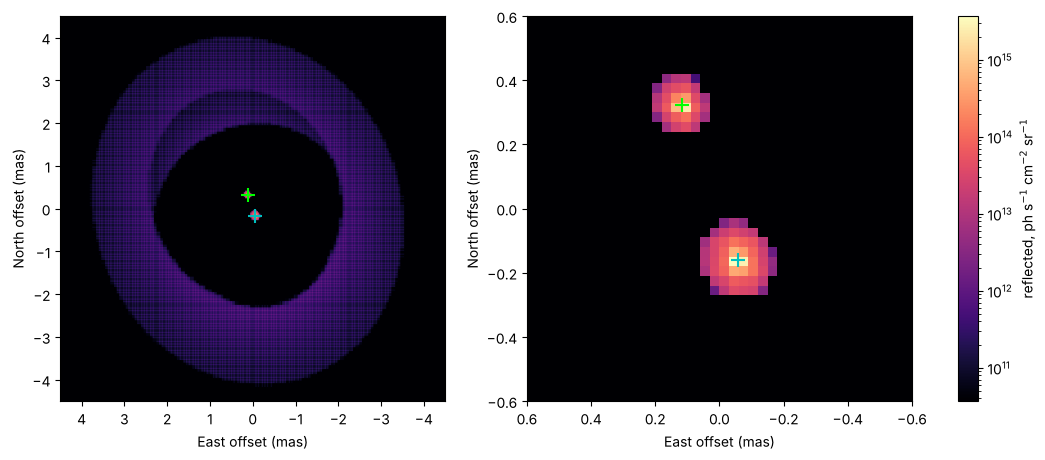

In [3]:
ext = [reg.nx / 2 * reg.scale / 1e3, -reg.nx / 2 * reg.scale / 1e3,
       -reg.ny / 2 * reg.scale / 1e3, reg.ny / 2 * reg.scale / 1e3]
ref = [L for L in m0.layers if L.grid.n > 1]
img = resample(ref)
cmap = plt.get_cmap("magma").copy()
cmap.set_bad(cmap(0.0))
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, lim in zip(ax, (None, 0.6)):
    im = a.imshow(np.where(img > 0, img, np.nan), origin="lower", extent=ext, cmap=cmap,
                  norm=LogNorm(vmin=img.max() * 1e-5, vmax=img.max()))
    for h, c in zip(holes0, ("c", "lime")):
        a.plot(h[0] / 1e3, h[1] / 1e3, "+", color=c, ms=10, mew=1.5)
    if lim:
        a.set_xlim(lim, -lim); a.set_ylim(-lim, lim)
    a.set_xlabel("East offset (mas)"); a.set_ylabel("North offset (mas)")
fig.colorbar(im, ax=ax, label="reflected, ph s$^{-1}$ cm$^{-2}$ sr$^{-1}$", fraction=0.03)

## Around the orbit

Here we show two key signatures from the binary, at nine different epochs: the coronae's line-of-sight velocities (from the energy shift `G` of their layers), anti-phased in the ratio of the masses (the heavier hole moves less), and the mean delay of the circumbinary disc's echo of each corona, which swings as each hole moves nearer to or farther from the side of the disc facing us.

The mini-discs' reflection is no use for the orbital velocity: their own Keplerian speeds (~0.08c at their inner edges) are far larger than the orbital ~1000 km/s.

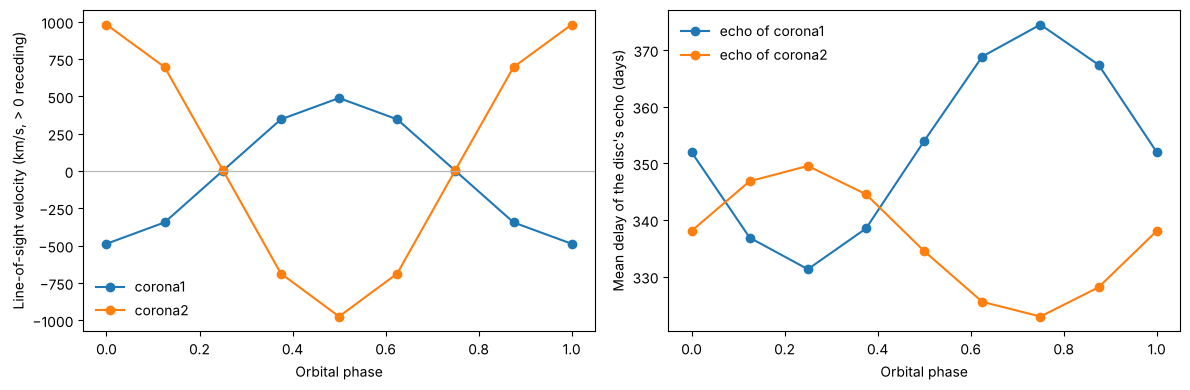

In [4]:
phases = np.linspace(0.0, 1.0, 9)
vel = {k: [] for k in ("corona1", "corona2")}
delay = {k: [] for k in ("corona1", "corona2")}
for ph in phases:
    m, _ = render(ph, level=9)
    for k in vel:
        vel[k].append((1 - m.layer(f"smbhb_{k}").maps["G"][0]) * 2.998e5)
        lay = m.layer(f"smbhb_cbd_{k}")
        delay[k].append((lay.maps["NORM"] * lay.maps["DELAY"]).sum() / lay.maps["NORM"].sum() / 86400)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for k, c in (("corona1", "C0"), ("corona2", "C1")):
    ax[0].plot(phases, vel[k], "o-", color=c, label=k)
    ax[1].plot(phases, delay[k], "o-", color=c, label=f"echo of {k}")
ax[0].axhline(0, color="0.7", lw=0.8)
ax[0].set_xlabel("Orbital phase"); ax[0].set_ylabel("Line-of-sight velocity (km/s, > 0 receding)")
ax[1].set_xlabel("Orbital phase"); ax[1].set_ylabel("Mean delay of the disc's echo (days)")
for a in ax:
    a.legend(frameon=False)
fig.tight_layout()

## Two echoes in one disc

The circumbinary disc actually reflects both coronae, each as its own layer following its own driver. Their delay distributions (the transfer functions summed over energy) differ because the two holes sit at different places relative to the disc: the delays shift around the orbit, a reverberation signature of a binary. That being said, these are over long enough time scales that sampling 

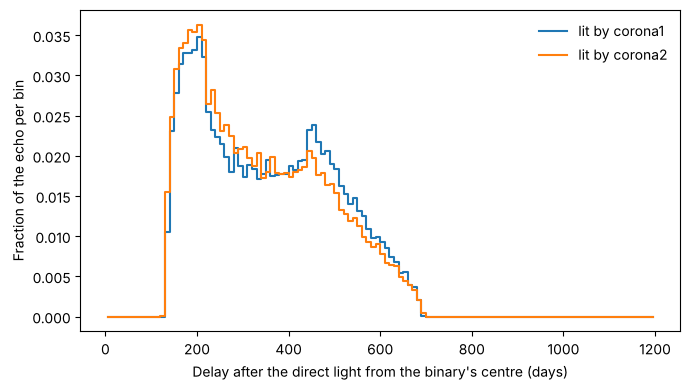

In [5]:
d_edges = np.linspace(0.0, 1200.0, 121)   # days
e_edges = np.linspace(0.5, 10.0, 20)
fig, ax = plt.subplots(figsize=(7, 4))
for k, c in (("corona1", "C0"), ("corona2", "C1")):
    lay = m0.layer(f"smbhb_cbd_{k}")
    psi = xm.transfer_function(lay, e_edges, d_edges * 86400.0)
    ax.step(0.5 * (d_edges[1:] + d_edges[:-1]), psi.sum(axis=0) / psi.sum(), where="mid", color=c,
            label=f"lit by {k}")
ax.set_xlabel("Delay after the direct light from the binary's centre (days)")
ax.set_ylabel("Fraction of the echo per bin")
ax.legend(frameon=False)
fig.tight_layout()

## Through XRISALIS: the pair moving on the sky

The model at two epochs a quarter of an orbit (25 years) apart, scaled to 0.03 photons/s/cm² in
total and observed for 5 ks each. The coronae dominate; the interferometer separates the two holes and
follows their motion. These use `xri_helpers.observe` (see the quickstart). Needs XRISALIS.

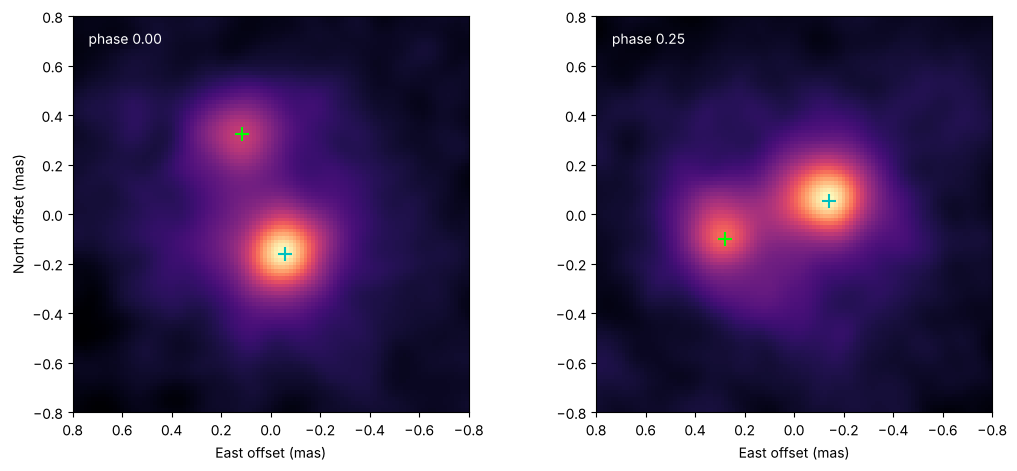

In [6]:
try:
    import xri_helpers as xri
except ImportError as err:   # XRISALIS not installed
    xri = None
    print("skipping:", err)

if xri is not None:
    fig, ax = plt.subplots(1, 2, figsize=(10.5, 4.6), constrained_layout=True)
    for a, ph in zip(ax, (0.0, 0.25)):
        model, holes = render(ph, level=9)
        obs = xri.observe(model, 5000.0, fov_arcsec=0.0016, total_flux=0.03,
                          seed=int(10 + 100 * ph))
        xri.show(a, obs, unit=1e3, gamma=1.0, label=f"phase {ph:.2f}")
        for h, c in zip(holes, ("c", "lime")):
            a.plot(h[0] / 1e3, h[1] / 1e3, "+", color=c, ms=10, mew=1.5)
    ax[0].set_ylabel("North offset (mas)")

The crosses are the true positions (cyan: the heavier hole). Spectrally, each corona's flux also carries
its orbital Doppler factor (G³ in the band photon flux).

**Not modelled:** general relativity (lensing of one hole's light by the other, gravitational redshift),
the gas streams feeding the mini-discs from the circumbinary disc, and any change of the orbit (here a
fixed Keplerian ellipse; give `KeplerOrbit` an eccentricity for an eccentric pair).